In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [23]:
pd.set_option('display.max_columns', None)  # показати всі колонки
pd.set_option('display.width', 1000)  # збільшити ширину рядка в символах

In [24]:
iris = load_iris()
X, y = iris.data, iris.target
feature_names = iris.feature_names
target_names = iris.target_names

df_iris = pd.DataFrame(X, columns=feature_names)
df_iris['target'] = y
df_iris['species'] = df_iris['target'].apply(lambda x: target_names[x])

print(df_iris.head(12))
print(f'Загальна кількість записів у датасеті: {len(df_iris)}\n')

    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  target species
0                 5.1               3.5                1.4               0.2       0  setosa
1                 4.9               3.0                1.4               0.2       0  setosa
2                 4.7               3.2                1.3               0.2       0  setosa
3                 4.6               3.1                1.5               0.2       0  setosa
4                 5.0               3.6                1.4               0.2       0  setosa
5                 5.4               3.9                1.7               0.4       0  setosa
6                 4.6               3.4                1.4               0.3       0  setosa
7                 5.0               3.4                1.5               0.2       0  setosa
8                 4.4               2.9                1.4               0.2       0  setosa
9                 4.9               3.1                1.5            

In [25]:
df_shuffled = df_iris.sample(frac=1, random_state=42).reset_index(drop=True)
print('Перші 12 рядків після випадкового перемішування:')
print(df_shuffled.head(12))
print()

Перші 12 рядків після випадкового перемішування:
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  target     species
0                 6.1               2.8                4.7               1.2       1  versicolor
1                 5.7               3.8                1.7               0.3       0      setosa
2                 7.7               2.6                6.9               2.3       2   virginica
3                 6.0               2.9                4.5               1.5       1  versicolor
4                 6.8               2.8                4.8               1.4       1  versicolor
5                 5.4               3.4                1.5               0.4       0      setosa
6                 5.6               2.9                3.6               1.3       1  versicolor
7                 6.9               3.1                5.1               2.3       2   virginica
8                 6.2               2.2                4.5               1.5  

Перші 12 записів ПІСЛЯ нормалізації (стандартизовані дані):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,0.310998,-0.592373,0.535409,0.000878
1,-0.173674,1.709595,-1.169714,-1.183812
2,2.249683,-1.052767,1.785832,1.448832
3,0.189830,-0.362176,0.421734,0.395774
4,1.159173,-0.592373,0.592246,0.264142
5,-0.537178,0.788808,-1.283389,-1.052180
6,-0.294842,-0.362176,-0.089803,0.132510
7,1.280340,0.098217,0.762758,1.448832
8,0.432165,-1.973554,0.421734,0.395774
9,-0.052506,-0.822570,0.080709,0.000878


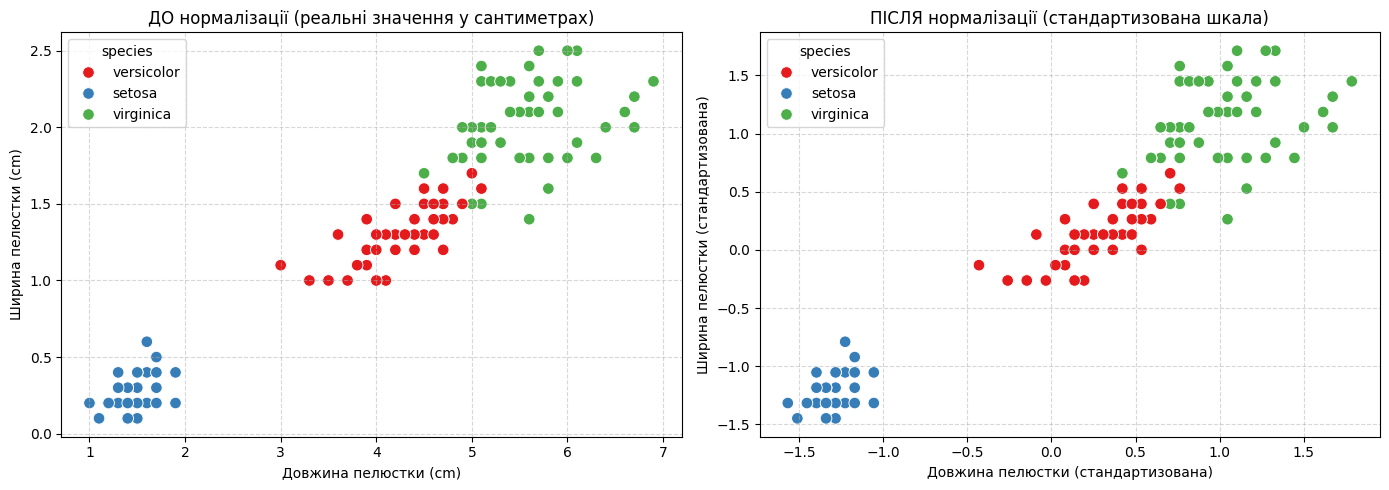

In [26]:
import seaborn as sns

feature_names = iris.feature_names
X_raw = df_shuffled[feature_names]

scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X_raw)

X_scaled = pd.DataFrame(X_scaled_array, columns=feature_names)

print('Перші 12 записів ПІСЛЯ нормалізації (стандартизовані дані):')
display(X_scaled.head(12))
print()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Графік ДО нормалізації
sns.scatterplot(
    data=df_shuffled,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='species',
    ax=axes[0],
    palette='Set1',
    s=70,
)
axes[0].set_title(
    'ДО нормалізації (реальні значення у сантиметрах)', fontsize=12
)
axes[0].set_xlabel('Довжина пелюстки (cm)')
axes[0].set_ylabel('Ширина пелюстки (cm)')
axes[0].grid(True, linestyle='--', alpha=0.5)

X_scaled_vis = X_scaled.copy()
X_scaled_vis['species'] = df_shuffled['species']

# Графік ПІСЛЯ нормалізації
sns.scatterplot(
    data=X_scaled_vis,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='species',
    ax=axes[1],
    palette='Set1',
    s=70,
)
axes[1].set_title('ПІСЛЯ нормалізації (стандартизована шкала)', fontsize=12)
axes[1].set_xlabel('Довжина пелюстки (стандартизована)')
axes[1].set_ylabel('Ширина пелюстки (стандартизована)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Загальна кількість зразків: 150
Розмір навчальної вибірки (train, 80%): 120 зразків
Розмір тестової вибірки (test, 20%): 30 зразків



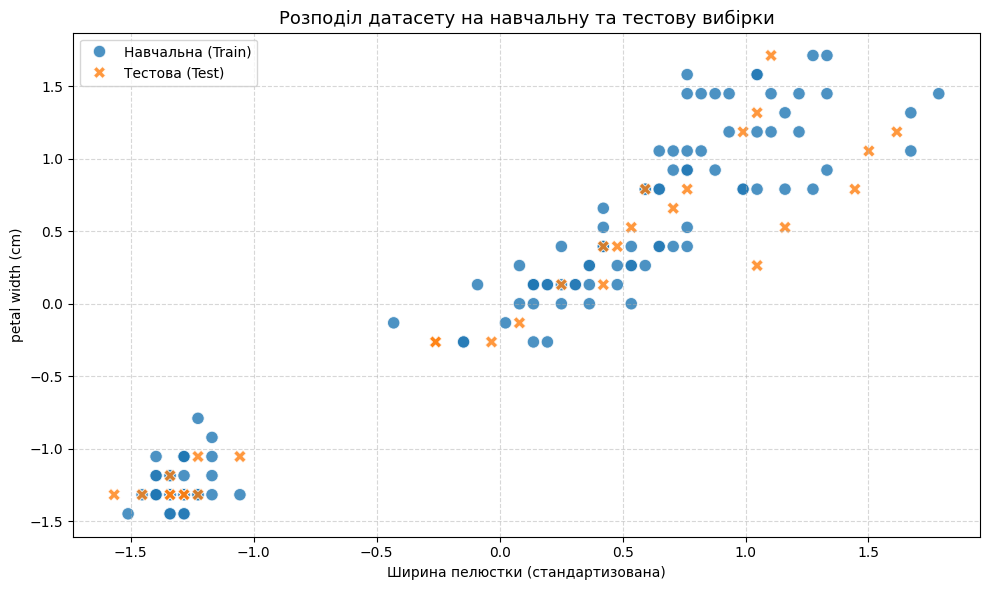

In [27]:
X_data = X_scaled_array
y_data = df_shuffled['target'].values
species_data = df_shuffled['species'].values

X_train, X_test, y_train, y_test, species_train, species_test = (
    train_test_split(
        X_data,
        y_data,
        species_data,
        test_size=0.2,
        random_state=42,
        stratify=y_data,
    )
)

print(f'Загальна кількість зразків: {len(X_data)}')
print(f'Розмір навчальної вибірки (train, 80%): {len(X_train)} зразків')
print(f'Розмір тестової вибірки (test, 20%): {len(X_test)} зразків\n')

plt.figure(figsize=(10, 6))

train_df = pd.DataFrame(X_train, columns=feature_names)
train_df['тип вибірки'] = 'Навчальна (Train)'

test_df = pd.DataFrame(X_test, columns=feature_names)
test_df['тип вибірки'] = 'Тестова (Test)'

vis_split_df = pd.concat([train_df, test_df], ignore_index=True)

sns.scatterplot(
    data=vis_split_df,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='тип вибірки',
    palette={'Навчальна (Train)': 'tab:blue', 'Тестова (Test)': 'tab:orange'},
    style='тип вибірки',
    s=80,
    alpha=0.8,
)

plt.title('Розподіл датасету на навчальну та тестову вибірки', fontsize=13)
plt.xlabel('Довжина пелюстки (стандартизована)')
plt.xlabel('Ширина пелюстки (стандартизована)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='')
plt.tight_layout()
plt.show()

Оптимальне значення k, знайдене під час експерименту: 11
Точність (Accuracy) на тестовій вибірці: 100.00%



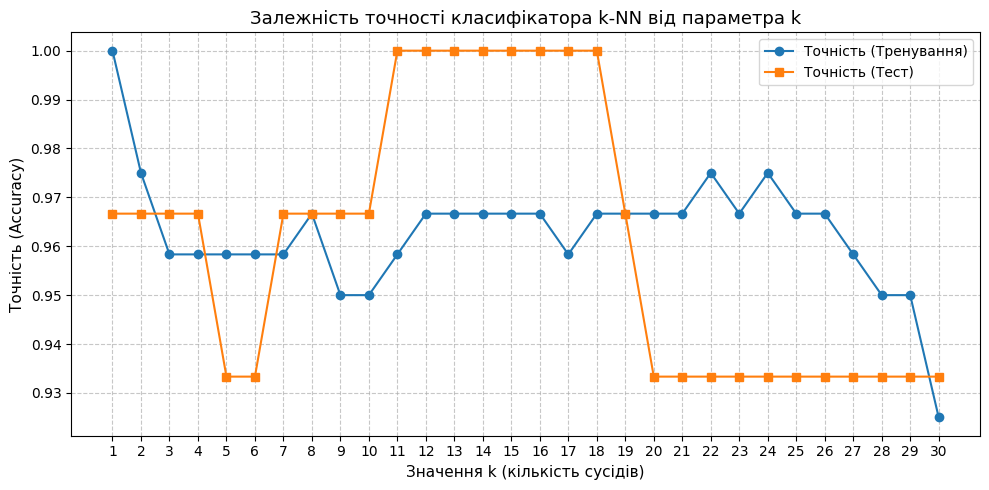

In [29]:
train_accuracies = []
test_accuracies = []
k_range = range(1, 31)

for k in k_range:

  knn = KNeighborsClassifier(n_neighbors=k)

  knn.fit(X_train, y_train)

  train_acc = knn.score(X_train, y_train)
  test_acc = knn.score(X_test, y_test)

  train_accuracies.append(train_acc)
  test_accuracies.append(test_acc)

best_k_idx = np.argmax(test_accuracies)
best_k = k_range[best_k_idx]
best_score = test_accuracies[best_k_idx]

print(f'Оптимальне значення k, знайдене під час експерименту: {best_k}')
print(f'Точність (Accuracy) на тестовій вибірці: {best_score * 100:.2f}%\n')

plt.figure(figsize=(10, 5))
plt.plot(
    k_range,
    train_accuracies,
    label='Точність (Тренування)',
    marker='o',
    color='tab:blue',
)
plt.plot(
    k_range,
    test_accuracies,
    label='Точність (Тест)',
    marker='s',
    color='tab:orange',
)

plt.title('Залежність точності класифікатора k-NN від параметра k', fontsize=13)
plt.xlabel('Значення k (кількість сусідів)', fontsize=11)
plt.ylabel('Точність (Accuracy)', fontsize=11)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()